# $\pi$: historical constructions as CMF trajectories

Exact rational approximants, sampled up to index 500.
$\delta_N=-1-\log|\alpha-p_N/q_N|/\log q_N$ and
$D_N=-\log_{10}|\alpha-p_N/q_N|$, with reduced $p_N/q_N$.
Published results and finite-depth measurements are distinct; source-index exceptions are stated below.

**Run status:**

- Mahler (1953): Depth-500 attempt stopped after 480 seconds.
- Bai (2026 preprint): Depth 500 requires 5,570,500 elementary shifts; exceeds the cleanup runtime budget.

In [ ]:
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 python-flint==0.9.0 matplotlib==3.11.2

## Setup

In [1]:
import sys
import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from IPython.display import Markdown, display
from ramanujantools.cmf.pfq import pFq
from ramanujantools.cmf.meijer_g import MeijerG
from cmfs import (
    gauss_arctan_pi_seeds, hata_pi, hata_pi_readout,
    hata_pi_seeds, mahler_pi_readout, meijer_g_fibre,
    salikhov_pi, salikhov_pi_seeds,
)

sys.set_int_max_str_digits(0)
DEPTHS = list(range(10, 501, 10))
results, accuracy = {}, {}
R = sp.Rational
u, v, w, m = sp.symbols("u v w m")
a, b, g = sp.symbols("a b g")
target = lambda: arb.pi()


def measure(approximant, target):
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(4 * q.bit_length() + 256):
        error = abs(target() - arb(p) / q)
        assert error > 0 and q > 1
        value = -1 - error.log() / arb(q).log()
        assert value.is_finite() and value.rad() < arb("1e-18")
        return float(value.mid()), float((-error.log() / arb(10).log()).mid())

## 1. Classical Gauss arctangent continued fraction

[NIST DLMF 4.25.4](https://dlmf.nist.gov/4.25.E4).

**CMF:** ${}_2F_1(-1)$, rank 2. **Start:** $(1/2,1;3/2)$. **Direction:** $(1,1;2)$.
**Readout:** $(PW)_0/(QW)_0=-2W_{10}/(2W_{00}-W_{10})$.
Source convergent index N uses N/2 CMF steps.

In [5]:
x0, x1, y0 = sp.symbols('x0 x1 y0')
cmf = pFq(2, 1, -1)
start = {x0: R(1, 2), x1: 1, y0: R(3, 2)}
trajectory = {x0: 1, x1: 1, y0: 2}
P, Q = gauss_arctan_pi_seeds(0)
walks = cmf.walk(trajectory, [M // 2 for M in DEPTHS], start)
approximants = [(P * W)[0] / (Q * W)[0] for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Gauss arctangent CF'] = (DEPTHS, deltas)
accuracy['Gauss arctangent CF'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.197786549055


## 2. Mahler (1953): the same polynomial forms, of degree $10$

[§§1–3](https://ems.press/books/dms/252/4986).

**CMF:** $G^{11,0}_{11,11}(-i)$, realified and dual; the library constructor supplies the field.
**Start/direction:** all eleven a-parameters start at 1 and increase by 1; b is fixed at 0.
**Readout:** $\operatorname{Re}(2ix/y)$ from the last two complex dual coordinates.
N is the source index. The bound 42 concerns the polynomial forms, not this scalar readout.

In [ ]:
cmf = meijer_g_fibre(MeijerG(11, 0, 11, 11), -sp.I).dual()
axes = sp.symbols('a0:11')
start = dict.fromkeys(axes, 1)
trajectory = dict.fromkeys(axes, 1)
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [mahler_pi_readout(W, 10) for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Mahler (1953)'] = (DEPTHS, deltas)
accuracy['Mahler (1953)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

Not computed: Depth-500 attempt stopped after 480 seconds.


## 3. Mignotte (1974): the Mahler--Mignotte polynomial forms

[Mignotte (1974), pp. 122--125](https://www.numdam.org/article/MSMF_1974__37__121_0.pdf).

**CMF:** $G^{6,0}_{6,6}(-i)$, realified and dual; the library constructor supplies the field.
**Start/direction:** all six a-parameters start at 1 and increase by 1; b is fixed at 0.
**Readout:** $\operatorname{Re}(2ix/y)$ from the last two complex dual coordinates.
N is the source index. The bound 20 concerns the polynomial forms, not this scalar readout.

In [9]:
cmf = meijer_g_fibre(MeijerG(6, 0, 6, 6), -sp.I).dual()
axes = sp.symbols('a0:6')
start = dict.fromkeys(axes, 1)
trajectory = dict.fromkeys(axes, 1)
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [mahler_pi_readout(W, 5) for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Mignotte (1974)'] = (DEPTHS, deltas)
accuracy['Mignotte (1974)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.414021309982


## 4. Hata (1993)

[Eqs. (1.3)–(1.4)](https://matwbn.icm.edu.pl/ksiazki/aa/aa63/aa6344.pdf).

**CMF:** moments of $(z-1)^u(z-2)^v(z-1-i)^w/z^m$, rank 3 over $\mathbb Q(i)$.
**Start:** $(2,2,2,4)$. **Direction:** $(2,2,2,3)$. Source index N uses N−1 steps.
**Readout:** $-4\operatorname{Im}(C/R)$ from $J=C+R\log(1+i)$.
The realified seed rows and readout are in `cmfs.py`.

In [11]:
cmf = hata_pi()
start = {u: 2, v: 2, w: 2, m: 4}
trajectory = {u: 2, v: 2, w: 2, m: 3}
C, Q = hata_pi_seeds()
walks = cmf.walk(trajectory, [N - 1 for N in DEPTHS], start)
approximants = [hata_pi_readout(W, C, Q) for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Hata (1993)'] = (DEPTHS, deltas)
accuracy['Hata (1993)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.151257332944


## 5. Borwein–Choi–Pigulla (2005): Gauss approximation of a Gregory tail

[Equations (8), (10), (12) and Example 3](https://www.sfu.ca/~schoia/paper/contfrac.pdf).

**CMF:** ${}_2F_1(-1)$, rank 2. **Start:** $(5/2,1;7/2)$. **Direction:** $(1,1;2)$.
**Readout:** $(PW)_0/(QW)_0=(80W_{00}-230W_{10})/(30W_{00}-75W_{10})$.
The Taylor-tail index is fixed at 2; source convergent index N uses N/2 CMF steps.

In [13]:
x0, x1, y0 = sp.symbols('x0 x1 y0')
cmf = pFq(2, 1, -1)
start = {x0: R(5, 2), x1: 1, y0: R(7, 2)}
trajectory = {x0: 1, x1: 1, y0: 2}
P, Q = gauss_arctan_pi_seeds(2)
walks = cmf.walk(trajectory, [M // 2 for M in DEPTHS], start)
approximants = [(P * W)[0] / (Q * W)[0] for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Borwein–Choi–Pigulla (2005), N=2'] = (DEPTHS, deltas)
accuracy['Borwein–Choi–Pigulla (2005), N=2'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.189435359634


## 6. Salikhov (2008/2010)

[Zeilberger–Zudilin, Part I](https://sites.math.rutgers.edu/~zeilberg/mamarim/mamarimPDF/pimeas.pdf).

**CMF:** rank-3 moments of $t^{2g}(t^4+6t^2+25)^a/(t^2-25)^b$.
**Start:** $(6,11,3)$. **Direction:** $(6,10,3)$. Source index N uses N−1 steps.
**Readout:** $-(CW)_0/(QW)_0$, from the exact rows of $K=C+Q\pi$.

In [15]:
cmf = salikhov_pi()
start = {a: 6, b: 11, g: 3}
trajectory = {a: 6, b: 10, g: 3}
C, Q = salikhov_pi_seeds('Salikhov')
walks = cmf.walk(trajectory, [N - 1 for N in DEPTHS], start)
approximants = [-(C * W)[0] / (Q * W)[0] for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Salikhov (2008/2010)'] = (DEPTHS, deltas)
accuracy['Salikhov (2008/2010)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.158864982330


## 7. Zeilberger–Zudilin (2020)

[Preprint](https://arxiv.org/abs/1912.06345).

**CMF:** $I(A,B,G)=K(2A,2B,G)$, the Salikhov CMF above ·
**Start:** $(1,2,1)$, that is $K(2,4,1)$ · **Direction:** $(2,3,2)$, that is
$(4,6,2)$ in $K$. Depth $N$ evaluates their integral $I_n$ with $n=2N+1$
, up to a constant factor.
The extraction is $-C/R$, as for Salikhov.

In [17]:
cmf = salikhov_pi()
start = {a: 2, b: 4, g: 1}
trajectory = {a: 4, b: 6, g: 2}
C, Q = salikhov_pi_seeds('Zeilberger-Zudilin')
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [-(C * W)[0] / (Q * W)[0] for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Zeilberger–Zudilin (2020)'] = (DEPTHS, deltas)
accuracy['Zeilberger–Zudilin (2020)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.164008748976


## 8. Bai (2026 preprint)

[Bai, Eqs. (1.1)–(1.8)](https://arxiv.org/html/2609.11276).

**CMF:** the rank-3 Salikhov moment field.
**Start:** $(0,1,0)$. **Direction:** $(3714,5570,1857)$; one period is one source index.
**Readout:** $-(CW)_0/(QW)_0$. Depth 500 requires 5,570,500 elementary shifts.

In [ ]:
cmf = salikhov_pi()
start = {a: 0, b: 1, g: 0}
trajectory = {a: 3714, b: 5570, g: 1857}
C, Q = salikhov_pi_seeds('Bai')
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [-(C * W)[0] / (Q * W)[0] for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Bai (2026 preprint)'] = (DEPTHS, deltas)
accuracy['Bai (2026 preprint)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

Not computed: Depth 500 requires 5,570,500 elementary shifts; exceeds the cleanup runtime budget.


## 9. OpenAI (2026 preprint): reference only

[the preprint](https://github.com/openai/math/blob/main/preprints/The-irrationality-exponent-of-pi-is-2-September-24-2026/paper.pdf).

**No verified CMF recovery; no delta calculation or final-table row.**

## Comparison

Only completed runs are shown. N follows each example’s stated index convention.

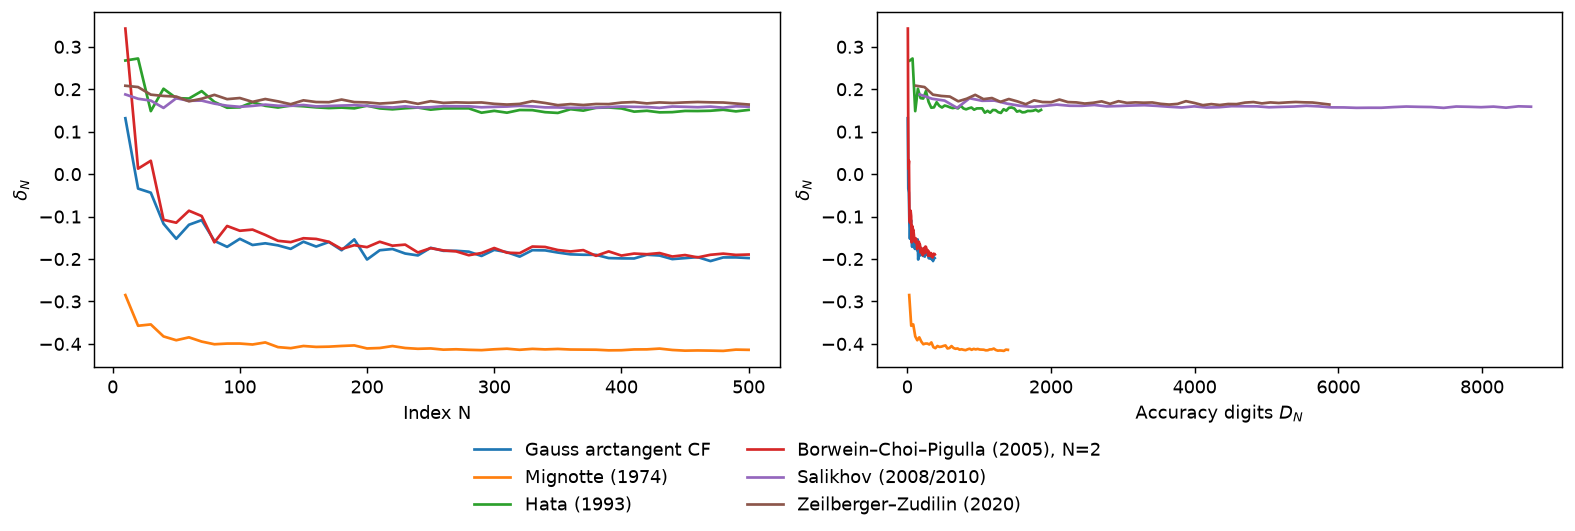

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, (depths, deltas) in results.items():
    axes[0].plot(depths, deltas, label=name)
    axes[1].plot(accuracy[name], deltas)
axes[0].set(xlabel="Index N", ylabel=r"$\delta_N$")
axes[1].set(xlabel=r"Accuracy digits $D_N$", ylabel=r"$\delta_N$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
plt.show()

## Historical overview

Only implemented CMF recoveries are listed. The measured column states the actual final index.

In [24]:
bounds = {
    'Gauss arctangent CF': '—',
    'Mahler (1953)': '$42$',
    'Mignotte (1974)': '$20$',
    'Hata (1993)': '$8.0161$',
    'Borwein–Choi–Pigulla (2005), N=2': '—',
    'Salikhov (2008/2010)': '$7.606308$',
    'Zeilberger–Zudilin (2020)': '$7.103205334137\\ldots$',
    'Bai (2026 preprint)': '$7.101862832357\\ldots$',
}
rows = ["| Construction | Published result | Measured delta |", "|:--|:--|:--|"]
for name, bound in bounds.items():
    if name in results:
        depths, deltas = results[name]
        value = f"{deltas[-1]:.12f} (N = {depths[-1]})"
    else:
        value = "Not computed"
    rows.append(f"| {name} | {bound} | {value} |")
display(Markdown("\n".join(rows)))

| Construction | Published result | Measured delta |
|:--|:--|:--|
| Gauss arctangent CF | — | -0.197786549055 (N = 500) |
| Mahler (1953) | $42$ | Not computed |
| Mignotte (1974) | $20$ | -0.414021309982 (N = 500) |
| Hata (1993) | $8.0161$ | 0.151257332944 (N = 500) |
| Borwein–Choi–Pigulla (2005), N=2 | — | -0.189435359634 (N = 500) |
| Salikhov (2008/2010) | $7.606308$ | 0.158864982330 (N = 500) |
| Zeilberger–Zudilin (2020) | $7.103205334137\ldots$ | 0.164008748976 (N = 500) |
| Bai (2026 preprint) | $7.101862832357\ldots$ | Not computed |